In [1]:
import os
from pathlib import Path
from typing import Literal, Optional, List

import numpy as np
import math
import uproot as uproot
import pickle
import pandas as pd
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white"})
import matplotlib.colors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
from matplotlib import gridspec
import seaborn as sns

os.environ["PROJECT_PATH"] = "/home/syebes/lambda-ana"
project_path = Path(os.environ["PROJECT_PATH"])
sys.path.append(str(project_path))
print(project_path/'data'/'df'/'test.df')

# My imports
from utils.utils import *

/home/syebes/lambda-ana/data/df/test.df


# Load dfs

In [2]:
lambda_file = "/exp/sbnd/data/users/syebes/eafData/dfs/lambda.df"
aurora_file = "/exp/sbnd/data/users/syebes/eafData/dfs/aurora_gen2.df"

In [3]:
with pd.HDFStore(aurora_file, 'r') as store:
    print(store.keys())

['/cuts', '/hdr', '/mcnu', '/pot']


In [4]:
lambda_mcnu_df = pd.read_hdf(lambda_file, key='mcnu') # Each entry is a subrun
lambda_hdr_df = pd.read_hdf(lambda_file, key='hdr') # Each entry is an event
lambda_cuts_df = pd.read_hdf(lambda_file, key='cuts') # Each entry is an pfp
lambda_pot_df = pd.read_hdf(lambda_file, key='pot') # 

aurora_mcnu_df = pd.read_hdf(aurora_file, key='mcnu') # Each entry is a subrun
aurora_hdr_df = pd.read_hdf(aurora_file, key='hdr') # Each entry is an event
aurora_cuts_df = pd.read_hdf(aurora_file, key='cuts') # Each entry is an pfp
aurora_pot_df = pd.read_hdf(aurora_file, key='pot') # 

In [5]:
mask = lambda_mcnu_df.is_lambda_signal

lambda_mcnu_df[mask].genie_mode.value_counts()

genie_mode
0    89725
Name: count, dtype: int64

In [7]:
lambda_pot = lambda_pot_df.TotalPOT.sum()
aurora_pot = aurora_pot_df.TotalPOT.sum()

print(f'Lambda POT: {lambda_pot}')
print(f'Aurora POT: {aurora_pot}')

pot_3y = 7e20

lambda_scale = pot_3y / lambda_pot
aurora_scale = pot_3y / aurora_pot

aurora_sgnl_mask = (aurora_cuts_df.is_lambda_signal == 1) | (aurora_cuts_df.is_sigma0_signal == 1)

lambda_cuts_df['scale'] = pot_3y / (lambda_pot + aurora_pot)
aurora_cuts_df['scale'] = aurora_scale
aurora_cuts_df.loc[aurora_sgnl_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot)

Lambda POT: 1.428596135616784e+23
Aurora POT: 5.401777280854836e+20


In [8]:
# Concatenate

mcnu_df = pd.concat([lambda_mcnu_df, aurora_mcnu_df])
hdr_df = pd.concat([lambda_hdr_df, aurora_hdr_df])
cuts_df = pd.concat([lambda_cuts_df, aurora_cuts_df])
pot_df = pd.concat([lambda_pot_df, aurora_pot_df])

In [9]:
mask = cuts_df.bcfm_score == -9999
cuts_df.loc[mask, 'bcfm_score'] = -1

## Counting

In [10]:
signal_mask = aurora_cuts_df.is_lambda_signal

len(aurora_cuts_df[signal_mask].groupby(level=(['__ntuple', 'entry'])).first())

482

In [11]:
mask = aurora_mcnu_df.is_lambda_signal

len(aurora_mcnu_df[mask])

1428

In [12]:
aurora_mcnu_df[mask].genie_mode.value_counts()

genie_mode
0    1428
Name: count, dtype: int64

# Define config parameters

In [13]:
import importlib
import utils.utils

importlib.reload(utils.utils)
from utils.utils import *

In [14]:
# =============
# Configuration
# =============


cuts_dict = {
        'Nu score' : Cut('nu_score','>', 0.5),
        'BCFM' : Cut('bcfm_score', '>', 0.04),
        'FV' : Cut('slc_in_fv', '==', 1, discrete=True),
        '# prim pfps' : RangeCut('n_prim_pfps', 2, 5,discrete=True, upper_inclusive=False),
        '# prim trks' : RangeCut('n_prim_trks', 1, 4,discrete=True, upper_inclusive=False),
        '# prim shwrs' : RangeCut('n_prim_shwrs', 0, 2,discrete=True, upper_inclusive=False),
        '# trks exiting' : Cut('n_trks_exit', '<', 2, discrete=True),
        'Gap' : Cut('max_gap', '>', 1),
}

palette = {
        "Signal":       "#2ecc71",
        "Nu background":   "#e74c3c",
        "Cosmics":     "#3498db",
        "Sigma0":     "purple",
}

categories = {
    "Signal" : ('is_lambda_signal', '==1'),
    #"Sigma0" : ('is_sigma0_signal', '==1'),
    "Cosmics":   ('genie_mode', "<0"),
    "Nu background": ('genie_mode', ">=0"),
}


# Analysis configuration
ana_cfg = AnalysisConfig(
    categories = categories,
    cuts=cuts_dict,
    palette=palette,
)


# Analysis driver
driver = AnalysisDriver(cuts_df, ana_cfg)

In [15]:
cp = driver.get_cuts_performance()

cp.style.format({
    "Signal" : "{:.0f}",
    "Sigma0" : "{:.0f}",
    "Cosmics" : "{:.2e}",
    "Nu background" : "{:.2e}",
    "Cut efficiency (%)": "{:.1f}",
    "Total efficiency (%)": "{:.1f}",
    "Purity (%)": "{:.3f}",
    "Bck rejection (%)": "{:.2f}",
})

,Stage,Cut value,Signal,Cosmics,Nu background,Cut efficiency (%),Total efficiency (%),Purity (%),Bck rejection (%)
0,Initial,[],417,1.85e+07,7.73e+06,100.0,100.0,0.002,0.00
1,Nu score,0.5,356,1.56e+06,5.18e+06,85.5,85.5,0.005,74.28
2,BCFM,0.04,325,6.31e+04,4.36e+06,91.2,78.0,0.007,83.13
3,FV,1,293,3.70e+04,3.21e+06,90.3,70.4,0.009,87.61
4,# prim pfps,"[2, 4]",277,2.51e+04,2.51e+06,94.5,66.6,0.011,90.32
5,# prim trks,"[1, 3]",274,2.28e+04,2.38e+06,98.6,65.7,0.011,90.82
6,# prim shwrs,"[0, 1]",265,2.11e+04,2.20e+06,96.8,63.5,0.012,91.54
7,# trks exiting,1,255,1.93e+04,2.08e+06,96.2,61.1,0.012,91.99
8,Gap,1,165,6.33e+03,6.87e+05,64.8,39.6,0.024,97.35


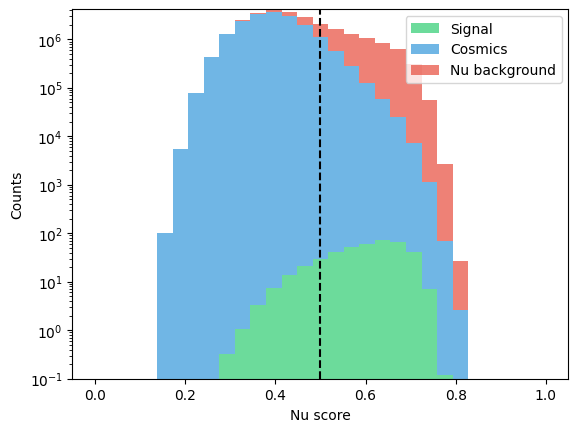

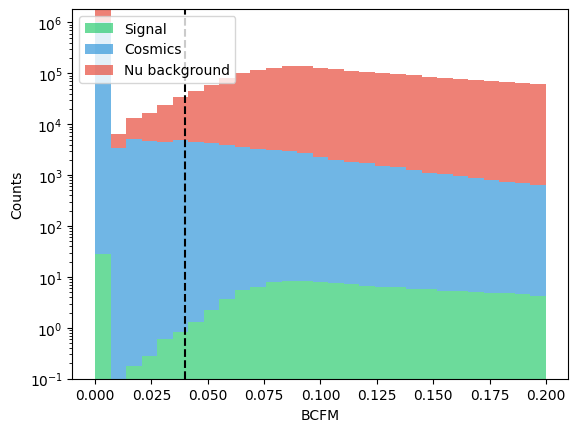

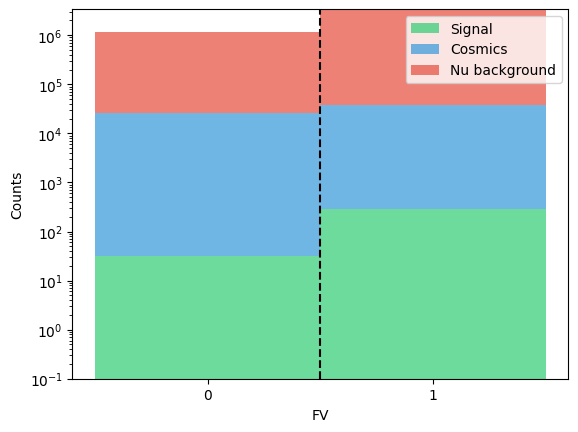

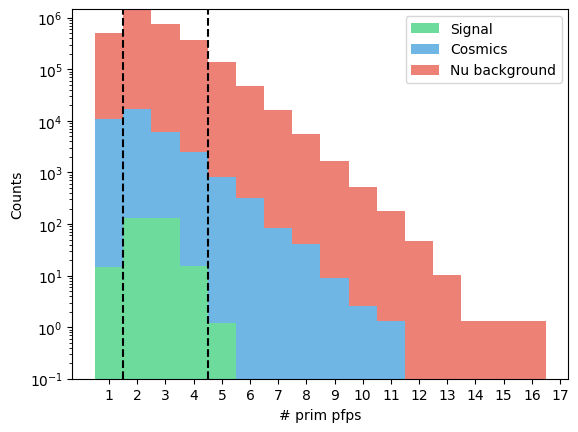

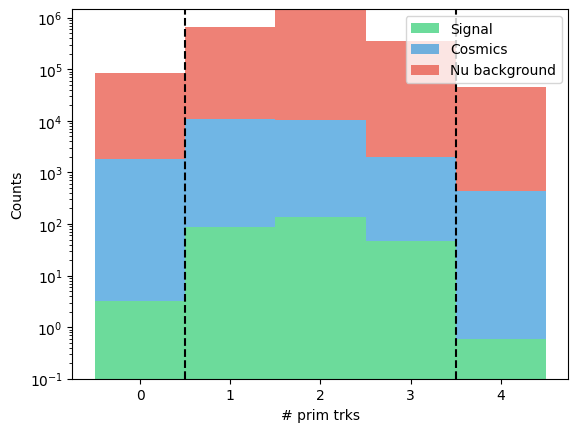

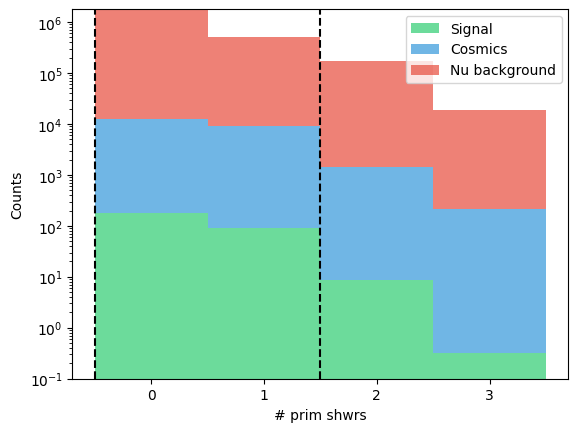

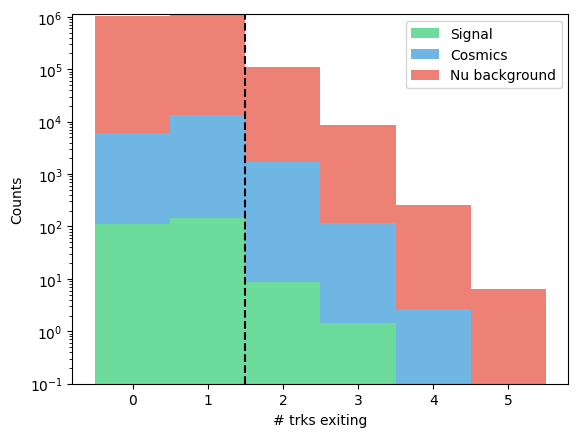

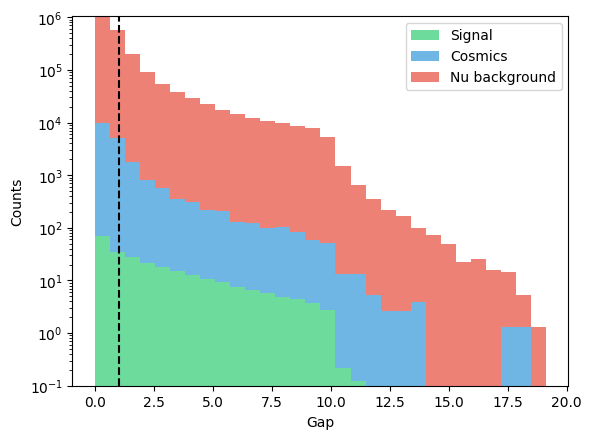

In [16]:
driver.plot_cuts(weights_col='scale', bins = 30)

# Get IDs

In [17]:
def save_ids(cuts_df, hdr_df, ana_cfg=ana_cfg, file_name='ids.txt'):
    id_cols = ['run', 'subrun', 'evt']
    
    driver = AnalysisDriver(cuts_df, ana_cfg)
    final_df = driver.get_final_df()
    final_idxs = final_df.index.droplevel(-1).unique()

    hdr_mask = hdr_df.index.isin(final_idxs)
    export_ids = hdr_df[hdr_mask][id_cols]

    export_ids.to_csv(
        file_name,
        sep=" ",
        index=False,
        header=False
    )

In [18]:
save_ids(aurora_cuts_df, aurora_hdr_df, file_name='aurora_ids.txt')
save_ids(lambda_cuts_df, lambda_hdr_df, file_name='lambda_ids.txt')

In [13]:
#aurora_hdr_df[id_cols]

In [14]:
len(lambda_mcnu_df.index.droplevel(-1).unique())

125751

In [15]:
len(lambda_cuts_df.index.droplevel(-1).unique())

125308

In [16]:
id_cols = ['run', 'subrun', 'evt']

my_driver = AnalysisDriver(lambda_cuts_df, ana_cfg)
final_df = my_driver.get_final_df()
final_idxs = final_df.index.droplevel(-1).unique()

In [17]:
final_idxs.names

FrozenList(['__ntuple', 'entry'])

In [18]:
len(final_idxs)

46072

In [19]:
len(lambda_cuts_df)

297678

In [20]:
lambda_cuts_df.is_lambda_signal.value_counts()

is_lambda_signal
False    212787
True      84891
Name: count, dtype: int64

In [26]:
lambda_cuts_df.index.names

FrozenList(['__ntuple', 'entry', 'rec.slc..index'])

In [30]:
signal_mask = lambda_cuts_df.is_lambda_signal

lambda_cuts_df.groupby(['__ntuple', 'entry'])["scale"].first().sum()

611.6856880408952